## Dijkstra vs SARSA (Common Routes Only)

This section compares both algorithms only on `(start_idx, target_idx)` pairs that exist in both CSV files.

- Success/completion is defined from `failed_error` (as requested).
- Completion-time comparisons include box plot, mean bar chart, and histogram.
- Route-level plots use a consistent `route_index` after sorting by `(start_idx, target_idx)`.

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re

# --- User-editable algorithm selectors ---
# Fill these two variables as needed
algo1 = "dij"
algo2 = "44a88465"

# --- Helpers ---
def resolve_algo_dir(runs_root: Path, algo_hint: str) -> Path:
    algo_hint = algo_hint.strip().lower()
    candidates = [p for p in runs_root.iterdir() if p.is_dir()]

    # 1) exact match
    exact = [p for p in candidates if p.name.lower() == algo_hint]
    if exact:
        return exact[0]

    # 2) startswith / contains
    fuzzy = [
        p for p in candidates
        if p.name.lower().startswith(algo_hint) or algo_hint in p.name.lower()
    ]
    if len(fuzzy) == 1:
        return fuzzy[0]
    if len(fuzzy) > 1:
        # choose shortest name as most specific compact match
        return sorted(fuzzy, key=lambda p: (len(p.name), p.name))[0]

    raise ValueError(f"No algorithm directory found under {runs_root} for hint: {algo_hint}")


def latest_test_csv(algo_dir: Path) -> Path:
    tests = [p for p in algo_dir.glob("test_*") if p.is_dir()]
    if not tests:
        raise ValueError(f"No test_* directories found in {algo_dir}")

    def test_index(path: Path):
        m = re.match(r"test_(\d+)$", path.name)
        return int(m.group(1)) if m else -1

    tests_sorted = sorted(
        tests,
        key=lambda p: (test_index(p), p.stat().st_mtime),
    )
    selected = tests_sorted[-1]
    csv_path = selected / "simulation_results.csv"
    if not csv_path.exists():
        raise ValueError(f"Missing simulation_results.csv in {selected}")
    return csv_path


def is_completed_from_failed_error(series: pd.Series) -> pd.Series:
    as_str = series.astype("string").str.strip().str.lower()
    return series.isna() | as_str.isin(["", "na", "nan", "none"])


# --- Inputs ---
runs_root = Path("../runs/trsp")
algo1_dir = resolve_algo_dir(runs_root, algo1)
algo2_dir = resolve_algo_dir(runs_root, algo2)

algo1_csv = latest_test_csv(algo1_dir)
algo2_csv = latest_test_csv(algo2_dir)

algo1_label = algo1_dir.name
algo2_label = algo2_dir.name

key_cols = ["start_idx", "target_idx"]
time_col = "total_time_taken"
path_col = "path_edges"
success_col = "failed_error"
required_cols = key_cols + [time_col, path_col, success_col]

# --- Load ---
df_algo1 = pd.read_csv(algo1_csv)
df_algo2 = pd.read_csv(algo2_csv)

for name, df in [(algo1_label, df_algo1), (algo2_label, df_algo2)]:
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"{name} missing required columns: {missing}")

# enforce types
for df in [df_algo1, df_algo2]:
    df["start_idx"] = pd.to_numeric(df["start_idx"], errors="coerce").astype("Int64")
    df["target_idx"] = pd.to_numeric(df["target_idx"], errors="coerce").astype("Int64")
    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")

# optional duplicate checks on route keys
dup_algo1 = df_algo1.duplicated(subset=key_cols).sum()
dup_algo2 = df_algo2.duplicated(subset=key_cols).sum()
print(f"Duplicate route keys -> {algo1_label}: {dup_algo1}, {algo2_label}: {dup_algo2}")
print(f"Using files -> {algo1_label}: {algo1_csv}")
print(f"Using files -> {algo2_label}: {algo2_csv}")

# --- SUCCESS-FIRST filtering ---
# Keep only successful rows per algorithm first
# success = failed_error is NA-like AND total_time_taken > 0
success_algo1_full = is_completed_from_failed_error(df_algo1[success_col]) & (df_algo1[time_col] > 0)
success_algo2_full = is_completed_from_failed_error(df_algo2[success_col]) & (df_algo2[time_col] > 0)

df_algo1_success = df_algo1.loc[success_algo1_full].copy()
df_algo2_success = df_algo2.loc[success_algo2_full].copy()

print(f"Successful rows -> {algo1_label}: {len(df_algo1_success)}/{len(df_algo1)}, {algo2_label}: {len(df_algo2_success)}/{len(df_algo2)}")

# --- Keep only common OD pairs among successful rows ---
pairs_algo1 = set(zip(df_algo1_success["start_idx"], df_algo1_success["target_idx"]))
pairs_algo2 = set(zip(df_algo2_success["start_idx"], df_algo2_success["target_idx"]))
common_pairs = pairs_algo1.intersection(pairs_algo2)

mask_algo1 = df_algo1_success.apply(lambda r: (r["start_idx"], r["target_idx"]) in common_pairs, axis=1)
mask_algo2 = df_algo2_success.apply(lambda r: (r["start_idx"], r["target_idx"]) in common_pairs, axis=1)

df_algo1_common = (
    df_algo1_success.loc[mask_algo1]
    .sort_values(key_cols)
    .reset_index(drop=True)
)
df_algo2_common = (
    df_algo2_success.loc[mask_algo2]
    .sort_values(key_cols)
    .reset_index(drop=True)
)

if len(df_algo1_common) != len(df_algo2_common):
    raise ValueError(
        f"Filtered row count mismatch: {algo1_label}={len(df_algo1_common)} vs {algo2_label}={len(df_algo2_common)}"
    )

# common route check
same_keys = (df_algo1_common[key_cols].values == df_algo2_common[key_cols].values).all()
if not same_keys:
    raise ValueError("Route ordering mismatch after sorting common pairs.")

# --- Adjustment: if path_edges are the same in both algos for a route,
# set both total_time_taken values to the lower of the two ---
path1 = df_algo1_common[path_col].astype("string").fillna("").str.strip()
path2 = df_algo2_common[path_col].astype("string").fillna("").str.strip()
same_path_mask = path1 == path2

min_shared_time = np.minimum(df_algo1_common[time_col].values, df_algo2_common[time_col].values)
df_algo1_common.loc[same_path_mask, time_col] = min_shared_time[same_path_mask.values]
df_algo2_common.loc[same_path_mask, time_col] = min_shared_time[same_path_mask.values]

print(f"Rows with identical path_edges adjusted to shared min time: {int(same_path_mask.sum())}")

# route index for x-axis alignment
df_algo1_common["route_index"] = np.arange(len(df_algo1_common))
df_algo2_common["route_index"] = np.arange(len(df_algo2_common))

# route labels
route_key = (
    df_algo1_common["start_idx"].astype(str)
    + "->"
    + df_algo1_common["target_idx"].astype(str)
)
df_algo1_common["route_key"] = route_key
df_algo2_common["route_key"] = route_key

# success summary on full dfs + comparison subset size
summary = pd.DataFrame(
    {
        "algorithm": [algo1_label, algo2_label],
        "completed_routes_in_full_df": [int(success_algo1_full.sum()), int(success_algo2_full.sum())],
        "total_routes_in_full_df": [len(df_algo1), len(df_algo2)],
        "routes_used_for_comparison": [len(df_algo1_common), len(df_algo2_common)],
    }
)
summary["success_rate_pct_full_df"] = 100 * summary["completed_routes_in_full_df"] / summary["total_routes_in_full_df"]

print(f"Common successful OD pairs: {len(common_pairs)}")
print(f"Rows after success+common filter -> {algo1_label}: {len(df_algo1_common)}, {algo2_label}: {len(df_algo2_common)}")
print("\nSuccess summary:")
display(summary)

# joined frame for route-level time difference
aligned = pd.DataFrame(
    {
        "route_index": df_algo1_common["route_index"],
        "start_idx": df_algo1_common["start_idx"],
        "target_idx": df_algo1_common["target_idx"],
        "route_key": df_algo1_common["route_key"],
        f"{algo1_label}_time": df_algo1_common[time_col],
        f"{algo2_label}_time": df_algo2_common[time_col],
    }
)
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"
aligned[diff_col] = aligned[f"{algo2_label}_time"] - aligned[f"{algo1_label}_time"]

time_summary = pd.DataFrame(
    {
        "algorithm": [algo1_label, algo2_label],
        "mean_time": [df_algo1_common[time_col].mean(), df_algo2_common[time_col].mean()],
        "median_time": [df_algo1_common[time_col].median(), df_algo2_common[time_col].median()],
        "min_time": [df_algo1_common[time_col].min(), df_algo2_common[time_col].min()],
        "max_time": [df_algo1_common[time_col].max(), df_algo2_common[time_col].max()],
    }
)

print("Time summary on successful common OD routes (after same-path min-time adjustment):")
display(time_summary)

display(aligned.head(10))

Duplicate route keys -> dijkstra: 0, 44a88465: 0
Using files -> dijkstra: ../runs/trsp/dijkstra/test_2/simulation_results.csv
Using files -> 44a88465: ../runs/trsp/44a88465/test_1/simulation_results.csv
Successful rows -> dijkstra: 301/301, 44a88465: 296/302
Rows with identical path_edges adjusted to shared min time: 199
Common successful OD pairs: 295
Rows after success+common filter -> dijkstra: 295, 44a88465: 295

Success summary:


,algorithm,completed_routes_in_full_df,total_routes_in_full_df,routes_used_for_comparison,success_rate_pct_full_df
0,dijkstra,301,301,295,100.000000
1,44a88465,296,302,295,98.013245


Time summary on successful common OD routes (after same-path min-time adjustment):


,algorithm,mean_time,median_time,min_time,max_time
0,dijkstra,337.535593,317.0,36.0,856.0
1,44a88465,333.555932,324.0,36.0,916.0


,route_index,start_idx,target_idx,route_key,dijkstra_time,44a88465_time,time_diff_44a88465_minus_dijkstra
0,0,0,1,0->1,36.0,36.0,0.0
1,1,0,2,0->2,128.0,128.0,0.0
2,2,0,3,0->3,179.0,156.0,-23.0
3,3,0,4,0->4,641.0,610.0,-31.0
4,4,0,5,0->5,72.0,72.0,0.0
5,5,0,6,0->6,307.0,283.0,-24.0
6,6,0,7,0->7,123.0,123.0,0.0
7,7,0,8,0->8,348.0,348.0,0.0
8,8,0,9,0->9,489.0,488.0,-1.0
9,9,0,10,0->10,398.0,374.0,-24.0


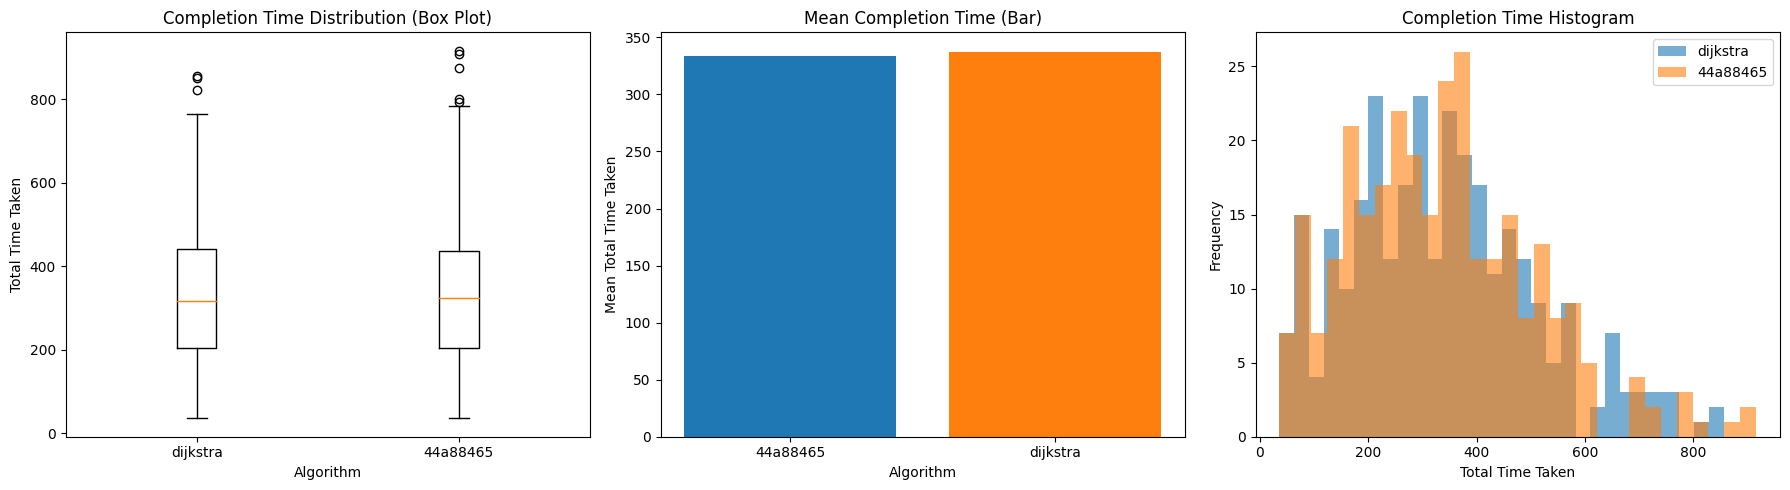

In [42]:
# --- Time comparison plots: box, mean bar, histogram ---
plot_df = pd.concat(
    [
        pd.DataFrame({"algorithm": algo1_label, "total_time_taken": df_algo1_common["total_time_taken"]}),
        pd.DataFrame({"algorithm": algo2_label, "total_time_taken": df_algo2_common["total_time_taken"]}),
    ],
    ignore_index=True,
)

means = (
    plot_df.groupby("algorithm", as_index=False)["total_time_taken"]
    .mean()
    .rename(columns={"total_time_taken": "mean_total_time_taken"})
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box plot
algorithms = [algo1_label, algo2_label]
box_data = [
    plot_df.loc[plot_df["algorithm"] == algo, "total_time_taken"].dropna().values
    for algo in algorithms
]
axes[0].boxplot(box_data, labels=algorithms)
axes[0].set_title("Completion Time Distribution (Box Plot)")
axes[0].set_xlabel("Algorithm")
axes[0].set_ylabel("Total Time Taken")

# Mean bar chart
axes[1].bar(means["algorithm"], means["mean_total_time_taken"], color=["#1f77b4", "#ff7f0e"])
axes[1].set_title("Mean Completion Time (Bar)")
axes[1].set_xlabel("Algorithm")
axes[1].set_ylabel("Mean Total Time Taken")

# Histogram overlay
bins = 30
axes[2].hist(df_algo1_common["total_time_taken"], bins=bins, alpha=0.6, label=algo1_label)
axes[2].hist(df_algo2_common["total_time_taken"], bins=bins, alpha=0.6, label=algo2_label)
axes[2].set_title("Completion Time Histogram")
axes[2].set_xlabel("Total Time Taken")
axes[2].set_ylabel("Frequency")
axes[2].legend()

plt.tight_layout()
plt.show()

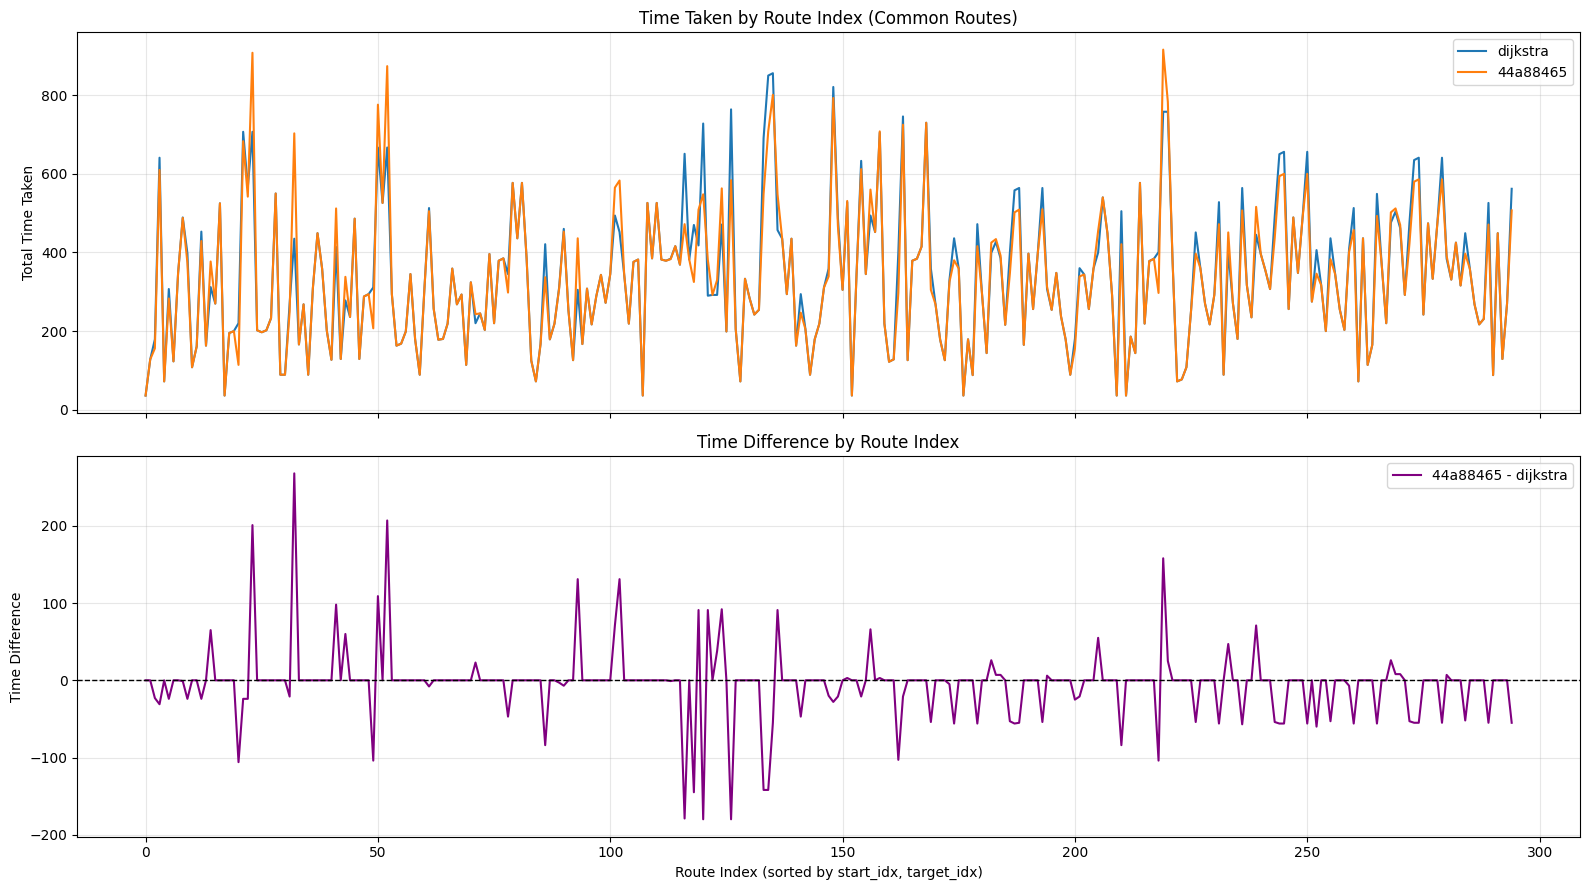

Mean time difference (44a88465 - dijkstra): -3.9796610169491524
Routes where 44a88465 is faster (diff < 0): 62
Routes where dijkstra is faster (diff > 0): 32
Routes with equal time: 201


In [43]:
# --- Route index plots: raw times and time difference ---
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

time_col_algo1 = f"{algo1_label}_time"
time_col_algo2 = f"{algo2_label}_time"
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"

axes[0].plot(aligned["route_index"], aligned[time_col_algo1], label=algo1_label, linewidth=1.5)
axes[0].plot(aligned["route_index"], aligned[time_col_algo2], label=algo2_label, linewidth=1.5)
axes[0].set_title("Time Taken by Route Index (Common Routes)")
axes[0].set_ylabel("Total Time Taken")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    aligned["route_index"],
    aligned[diff_col],
    color="purple",
    linewidth=1.5,
    label=f"{algo2_label} - {algo1_label}",
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Time Difference by Route Index")
axes[1].set_xlabel("Route Index (sorted by start_idx, target_idx)")
axes[1].set_ylabel("Time Difference")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean time difference ({algo2_label} - {algo1_label}):", aligned[diff_col].mean())
print(f"Routes where {algo2_label} is faster (diff < 0):", (aligned[diff_col] < 0).sum())
print(f"Routes where {algo1_label} is faster (diff > 0):", (aligned[diff_col] > 0).sum())
print("Routes with equal time:", (aligned[diff_col] == 0).sum())

Top 10 BEST routes for 44a88465 vs dijkstra (most negative diff):


,route_index,route_key,dijkstra_time,44a88465_time,time_diff_44a88465_minus_dijkstra
120,120,4->5,728.0,548.0,-180.0
126,126,4->11,764.0,584.0,-180.0
116,116,4->0,651.0,472.0,-179.0
118,118,4->2,470.0,325.0,-145.0
133,133,4->18,691.0,549.0,-142.0
134,134,4->19,850.0,708.0,-142.0
20,20,0->21,220.0,114.0,-106.0
49,49,1->21,311.0,207.0,-104.0
218,218,7->21,401.0,297.0,-104.0
162,162,5->21,400.0,297.0,-103.0


Top 10 WORST routes for 44a88465 vs dijkstra (most positive diff):


,route_index,route_key,dijkstra_time,44a88465_time,time_diff_44a88465_minus_dijkstra
32,32,1->4,435.0,703.0,268.0
52,52,1->24,667.0,874.0,207.0
23,23,0->24,707.0,908.0,201.0
219,219,7->22,758.0,916.0,158.0
93,93,3->7,305.0,436.0,131.0
102,102,3->16,452.0,583.0,131.0
50,50,1->22,667.0,776.0,109.0
41,41,1->13,414.0,512.0,98.0
124,124,4->9,471.0,563.0,92.0
119,119,4->3,418.0,509.0,91.0


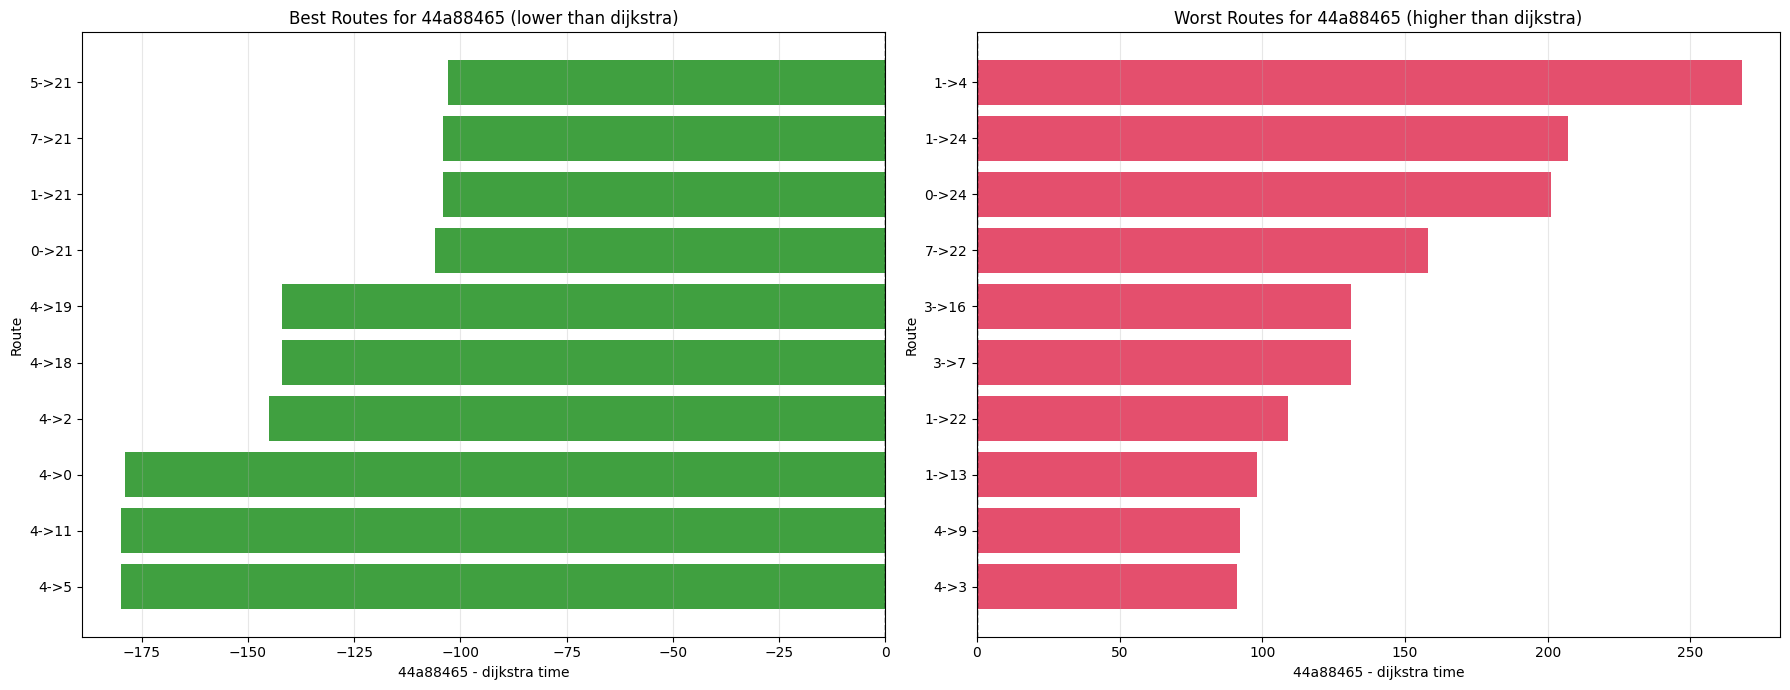

In [44]:
# --- Best and worst routes between the two algorithms ---
# diff_col is defined as: algo2_time - algo1_time
#   negative -> algo2 faster, positive -> algo1 faster

top_k = 10

time_col_algo1 = f"{algo1_label}_time"
time_col_algo2 = f"{algo2_label}_time"
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"

best_for_algo2 = aligned.nsmallest(top_k, diff_col).copy()
worst_for_algo2 = aligned.nlargest(top_k, diff_col).copy()

show_cols = ["route_index", "route_key", time_col_algo1, time_col_algo2, diff_col]

print(f"Top {top_k} BEST routes for {algo2_label} vs {algo1_label} (most negative diff):")
display(best_for_algo2[show_cols])

print(f"Top {top_k} WORST routes for {algo2_label} vs {algo1_label} (most positive diff):")
display(worst_for_algo2[show_cols])

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=False)

left_df = best_for_algo2.sort_values(diff_col, ascending=True)
right_df = worst_for_algo2.sort_values(diff_col, ascending=True)

axes[0].barh(left_df["route_key"], left_df[diff_col], color="green", alpha=0.75)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title(f"Best Routes for {algo2_label} (lower than {algo1_label})")
axes[0].set_xlabel(f"{algo2_label} - {algo1_label} time")
axes[0].set_ylabel("Route")
axes[0].grid(axis="x", alpha=0.3)

axes[1].barh(right_df["route_key"], right_df[diff_col], color="crimson", alpha=0.75)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title(f"Worst Routes for {algo2_label} (higher than {algo1_label})")
axes[1].set_xlabel(f"{algo2_label} - {algo1_label} time")
axes[1].set_ylabel("Route")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()